Dataset:
   Maths_Marks  Science_Marks
0           81             32
1           44             30
2           90             34
3           50             43
4           53             56
5           32             38
6           51             44
7           82             71
8           31             80
9           59             92

Number of data points: 100

Dataset saved as student_marks_dataset.csv

Missing values:
Maths_Marks      0
Science_Marks    0
dtype: int64

Average marks:
Maths_Marks      64.18
Science_Marks    64.85
dtype: float64


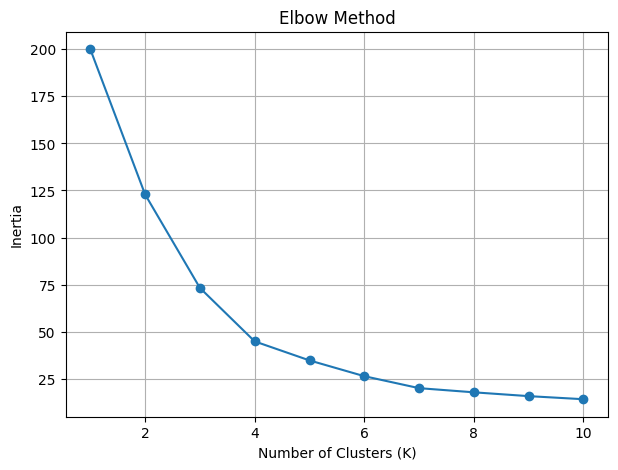


Optimal number of clusters: 3

Clustered Dataset:
   Maths_Marks  Science_Marks  Cluster
0           81             32        0
1           44             30        1
2           90             34        0
3           50             43        1
4           53             56        1
5           32             38        1
6           51             44        1
7           82             71        0
8           31             80        2
9           59             92        2

Number of students in each cluster:
Cluster
0    41
1    28
2    31
Name: count, dtype: int64

Average marks in each cluster:
         Maths_Marks  Science_Marks
Cluster                            
0              84.46          62.88
1              46.96          42.57
2              52.90          87.58

Silhouette Score: 0.406


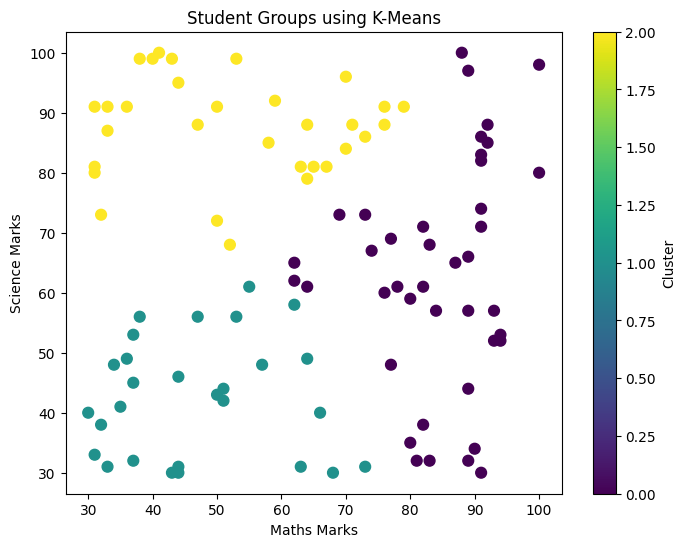


Clustered dataset saved as:
student_marks_kmeans_result.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


K-Means clustering completed successfully!


In [2]:
# ============================================================
# K-MEANS CLUSTERING
# SIMPLE STUDENT MARKS DATASET
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# ------------------------------------------------------------
# 2. CREATE SIMPLE UNSUPERVISED DATASET
# ------------------------------------------------------------

# 100 students
# Only two features:
# Maths marks and Science marks

np.random.seed(42)

maths = np.random.randint(30, 101, 100)
science = np.random.randint(30, 101, 100)

df = pd.DataFrame({
    "Maths_Marks": maths,
    "Science_Marks": science
})

print("Dataset:")
print(df.head(10))

print("\nNumber of data points:", len(df))

# ------------------------------------------------------------
# 3. SAVE DATASET
# ------------------------------------------------------------

df.to_csv(
    "student_marks_dataset.csv",
    index=False
)

print("\nDataset saved as student_marks_dataset.csv")

# ------------------------------------------------------------
# 4. CHECK DATASET
# ------------------------------------------------------------

print("\nMissing values:")
print(df.isnull().sum())

print("\nAverage marks:")
print(df.mean())

# ------------------------------------------------------------
# 5. SELECT FEATURES
# ------------------------------------------------------------

X = df[
    [
        "Maths_Marks",
        "Science_Marks"
    ]
]

# ------------------------------------------------------------
# 6. STANDARDIZE DATA
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# ------------------------------------------------------------
# 7. ELBOW METHOD
# ------------------------------------------------------------

inertia = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

# ------------------------------------------------------------
# 8. PLOT ELBOW GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.plot(
    range(1, 11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.grid(True)

plt.show()

# ------------------------------------------------------------
# 9. SELECT NUMBER OF CLUSTERS
# ------------------------------------------------------------

# From the Elbow graph, select K.
# For this simple dataset, we use 3 clusters.

k = 3

print("\nOptimal number of clusters:", k)

# ------------------------------------------------------------
# 10. APPLY K-MEANS
# ------------------------------------------------------------

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nClustered Dataset:")
print(df.head(10))

# ------------------------------------------------------------
# 11. COUNT STUDENTS IN EACH CLUSTER
# ------------------------------------------------------------

print("\nNumber of students in each cluster:")

print(
    df["Cluster"].value_counts().sort_index()
)

# ------------------------------------------------------------
# 12. FIND AVERAGE VALUES
# ------------------------------------------------------------

print("\nAverage marks in each cluster:")

average_values = df.groupby("Cluster")[
    ["Maths_Marks", "Science_Marks"]
].mean()

print(
    average_values.round(2)
)

# ------------------------------------------------------------
# 13. SILHOUETTE SCORE
# ------------------------------------------------------------

score = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("\nSilhouette Score:", round(score, 3))

# ------------------------------------------------------------
# 14. PLOT CLUSTERS
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    df["Maths_Marks"],
    df["Science_Marks"],
    c=df["Cluster"],
    cmap="viridis",
    s=60
)

plt.xlabel("Maths Marks")
plt.ylabel("Science Marks")

plt.title("Student Groups using K-Means")

plt.colorbar(label="Cluster")

plt.show()

# ------------------------------------------------------------
# 15. SAVE CLUSTERED DATASET
# ------------------------------------------------------------

df.to_csv(
    "student_marks_kmeans_result.csv",
    index=False
)

print("\nClustered dataset saved as:")
print("student_marks_kmeans_result.csv")

# ------------------------------------------------------------
# 16. DOWNLOAD DATASETS
# ------------------------------------------------------------

from google.colab import files

files.download(
    "student_marks_dataset.csv"
)

files.download(
    "student_marks_kmeans_result.csv"
)

print("\nK-Means clustering completed successfully!")